In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals, bh_projections

In [2]:
N = 67
sigma = 2

## theta and phi grids used for radon transform
thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)


## theta and phi grids used for spherical Bessel projection
## it oversamples by a factor 2 to show how.
## If you do not want to oversample, replace "2" by "1" here
## and make a change indicated in a comment below

## EV: I changed this a lot from the original, need to double check
# n_phi = 2*N
# n_theta = 2*N

# s = 2
# n_phi = N
# n_theta = N
# nz = s*N

# thetas2 = np.linspace(0, np.pi, n_theta, endpoint=True)
# phis2 = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

z = utils.generate_centered_gaussian(N=N, d=3, sigma=sigma)
f_1 = transforms.translate_3d(z, 0, 10, 0)     # move centered blob down
f_2 = transforms.translate_3d(z, 0, -15, -20)  # move blob far left and up
f_3 = transforms.translate_3d(z, 10, 0, 10)    # move blob back and right
f = f_1 + f_2 + f_3 
f = transforms.translate_3d(f, 0, 10, 0)

f = signals.Signal(f, d=3, rescale=True).preprocess_signals()[0]  # maybe should start to include rescale

# ## compute Radon transform
t = time.time()
Pf_rt = transforms.Transform(f, d=3).radon_transform()[0]
print('Radon Transform :', time.time() - t)

### compute spherical Bessel projection
#if you do not want to oversample, remove "[:,::2,:]"
# and the "2" in the comment above
t = time.time()
Pf_bh = transforms.Transform(f, d=3).ball_harmonic_projections()
# # P2 = bh_projections.projs(f, N, nz, n_theta, n_phi, max_l=30)[:,::2,:].real
print('   BH Transform :', time.time() - t)

# Pf_bg.shape
# np.allclose(Pf_bh, P2)

Radon Transform : 0.04662895202636719
   BH Transform : 4.209265947341919


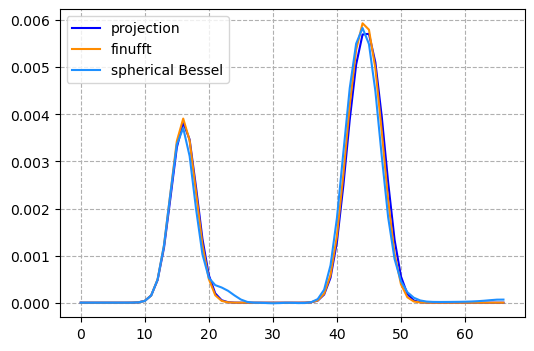

  theta gt:  47.0
 theta idx:  46.36363636363637
    phi gt:  117.0
   phi idx:  118.20895522388061


In [3]:
#rotation Euler angles in ZYZ convention

np.random.seed(0)

omega = np.deg2rad(np.random.randint(0,360))
theta = np.deg2rad(np.random.randint(0,180))
phi = np.deg2rad(np.random.randint(0,360))


#rotate F by the angles above
g = transforms.rotate_voxel_zyz(f, omega, theta, phi, order=1)  

phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

### not oversampling the angles yet
# phi_idx2 = np.argmin(abs(phis2 - abs(phi)))
# theta_idx2 = np.argmin(abs(thetas2 - abs(theta)))

plt.figure(figsize=(6,4))

v1 = np.sum(g, axis=(0,1)) * (2-2/N)**2/N**2 # okay scale here because commutes?
v2 = Pf_rt[phi_idx, :, theta_idx]
v3 = Pf_bh[phi_idx, :, theta_idx]

plt.plot(v1, color='blue', label='projection')
plt.plot(v2, color='darkorange', label='finufft')
plt.plot(v3, color='dodgerblue', label='spherical Bessel')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print('  theta gt: ', np.rad2deg(theta))
print(' theta idx: ', np.rad2deg(thetas)[theta_idx])
# print('theta idx2: ', np.rad2deg(thetas2)[theta_idx2])
print('    phi gt: ', np.rad2deg(phi))
print('   phi idx: ', np.rad2deg(phis)[phi_idx])
# print('  phi idx2: ', np.rad2deg(phis2)[phi_idx2])

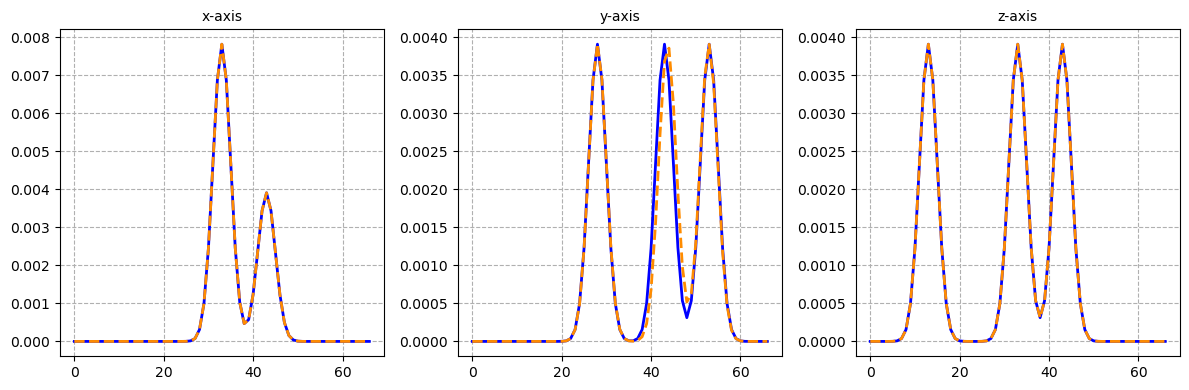

In [4]:
plots.orthogonal_1D_projection_comparison_plot(f * (2-2/N)**2/N**2 , Pf_rt)

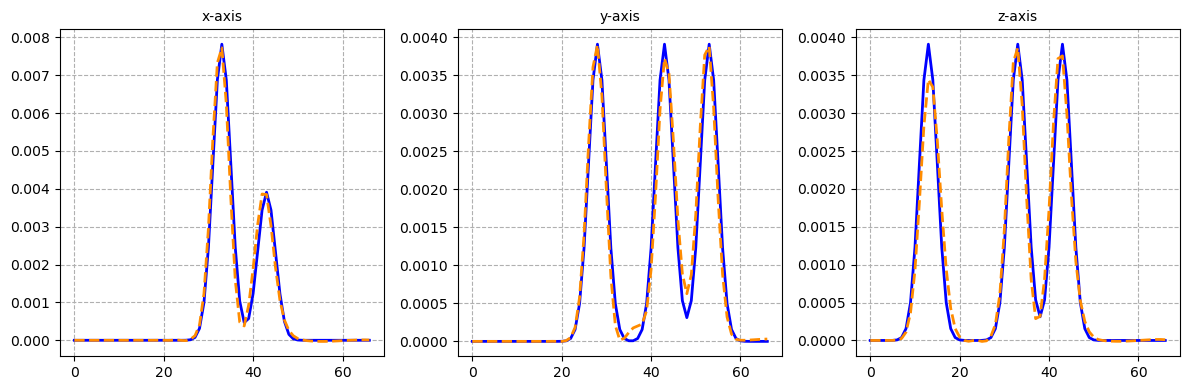

In [5]:
plots.orthogonal_1D_projection_comparison_plot(f * (2-2/N)**2/N**2 , Pf_bh)

In [6]:
# plots.orthogonal_1D_projection_comparison_plot(f / np.amax(f), P.real / np.amax(P.real) * N)
# plots.orthogonal_1D_projection_comparison_plot(f / np.amax(f), P2.real / np.amax(P2.real) * N)